In [2]:
import pandas as pd
import numpy as np


In [3]:
df_complete = pd.read_csv("../1.data/2.processed/dados_marco_abril.csv")
df_complete.head()

,id_compra,score_1,score_2,score_3,score_4,score_5,score_6,pais,score_7,produto,...,score_8,score_9,score_10,data_compra,valor_compra,score_fraude_modelo,fraude,entrega_doc_1,entrega_doc_2,entrega_doc_3
0,1,4,0.7685,94436.24,20.0,0.444828,1.0,BR,5,Máquininha Corta Barba Cabelo Peito Perna Pelo...,...,0.883598,240.0,102.0,2020-03-27 11:51:16,5.64,66,0,1,NaN,N
1,3,4,0.7455,242549.09,3.0,0.000000,19.0,AR,23,Bicicleta Mountain Fire Bird Rodado 29 Alumini...,...,0.516368,1779.0,77.0,2020-03-25 18:13:38,339.32,95,0,1,NaN,N
2,7,4,0.5962,7121.78,2.0,0.398000,0.0,BR,11,"Corpinho Avulso Joseph, Josepha Ou Placa Sem Sexo",...,0.204991,127.0,125.0,2020-03-22 19:20:24,10.56,71,0,0,NaN,N
3,10,4,0.4759,40143.12,50.0,0.000000,41.0,AR,3,Gamepad Joystick Para Telefono Celular Android...,...,0.735790,4701.0,940.0,2020-03-11 15:06:38,30.48,60,0,1,NaN,Y
4,11,4,0.8353,121926.06,39.0,0.186957,34.0,BR,24,Escova Dental Curaprox 5460 Ultra Soft Com 3 U...,...,0.943792,3248.0,132.0,2020-03-15 19:18:50,14.85,10,0,1,Y,Y


In [4]:
## tratamento de inconsistencias

import datetime


-coluna `data_compra` para datetime
-ver se existem linhas duplicadas
-ver sobre os valores nulos
-verificar quantas fraudes tem no dataset

SyntaxError: invalid syntax (3323734972.py, line 6)

In [5]:
df_complete['data_compra'].head()

0    2020-03-27 11:51:16
1    2020-03-25 18:13:38
2    2020-03-22 19:20:24
3    2020-03-11 15:06:38
4    2020-03-15 19:18:50
Name: data_compra, dtype: str

In [6]:
df_complete['data_compra'] = pd.to_datetime(df_complete['data_compra'])
df_complete['data_compra'].head()

0   2020-03-27 11:51:16
1   2020-03-25 18:13:38
2   2020-03-22 19:20:24
3   2020-03-11 15:06:38
4   2020-03-15 19:18:50
Name: data_compra, dtype: datetime64[us]

In [7]:
## linhas duplicadas

duplicated_lines = df_complete[df_complete.duplicated()]
duplicated_lines

,id_compra,score_1,score_2,score_3,score_4,score_5,score_6,pais,score_7,produto,...,score_8,score_9,score_10,data_compra,valor_compra,score_fraude_modelo,fraude,entrega_doc_1,entrega_doc_2,entrega_doc_3
78453,64219,4,1.0000,535.08,50.0,0.259026,4.0,BR,1,Alavanca Full Auto #38 We M92 Samurai Edge,...,0.572792,2138.0,452.0,2020-04-12 21:17:45,18.87,40,0,1,NaN,Y
78839,121664,4,0.8129,37474.43,50.0,0.000000,13.0,BR,10,Coelho Sansão Pelúcia 50cm Turma Da Mônica Ori...,...,0.229014,3862.0,996.0,2020-04-03 07:41:50,31.95,24,0,1,NaN,Y
78892,3204,4,0.7794,43342.44,50.0,1.331104,86.0,BR,29,Organizador Porta Comprimidos E Remédios - 7 D...,...,0.184518,2133.0,764.0,2020-04-07 21:07:14,2.90,7,0,1,NaN,Y
79353,124754,2,0.5157,32489.48,5.0,0.000000,108.0,AR,32,Riel 2mts Para Mensula Doble Reforzado Todoest...,...,0.486794,5809.0,143.0,2020-04-21 20:18:09,37.63,6,0,1,NaN,Y
79904,10437,4,0.7660,64396.62,50.0,0.089634,29.0,BR,24,Kit 10 Mini Spot Embutir Led Redondo 3w Branco...,...,0.546726,2907.0,438.0,2020-04-18 20:03:43,15.16,47,0,1,NaN,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148752,120814,4,0.5727,29145.32,1.0,0.247198,2.0,AR,15,Muñeco Transformer Simil Optimus Prime Bumbleb...,...,0.768834,745.0,0.0,2020-04-08 12:17:01,26.35,30,0,1,NaN,N
148919,126985,4,0.7288,186213.43,34.0,0.406953,1.0,BR,30,Lente Retrovisor Hb20 2012 2013 2014 2015 16 1...,...,0.289483,777.0,116.0,2020-04-20 19:45:43,9.44,47,0,1,NaN,Y
149051,13954,4,0.7735,118454.38,50.0,0.141068,28.0,BR,6,Arranjo Noah Orquídea Toque Real - Decoração P...,...,0.968042,2660.0,715.0,2020-04-21 15:02:39,23.12,70,0,1,NaN,Y
149078,48127,4,0.6380,167793.89,1.0,0.304539,8.0,BR,42,Toner Tn2340 Para Dcp-l2520 L2520d L2520dw Dcp...,...,0.428939,1548.0,0.0,2020-04-06 20:57:56,10.22,30,0,1,NaN,N


In [8]:
## Quantidade de vezes que a linha se repetiu
df_complete[df_complete.duplicated(keep=False)].value_counts().reset_index(name='qtd')

,id_compra,score_1,score_2,score_3,score_4,score_5,score_6,pais,score_7,produto,...,score_9,score_10,data_compra,valor_compra,score_fraude_modelo,fraude,entrega_doc_1,entrega_doc_2,entrega_doc_3,qtd
0,8972,4,0.5897,26755.88,2.0,0.000000,4.0,AR,1,Fuente Switching 12v Led Camaras Metalica 5a 6...,...,203.0,203.0,2020-04-09 18:34:37,51.61,68,0,1,N,Y,2
1,129795,4,0.8240,1013530.22,50.0,0.000000,5.0,BR,28,Kit Embreagem Siena 1.0 Mpi 8v Fire 2012 2013 ...,...,1031.0,627.0,2020-04-15 10:48:24,47.88,3,0,1,Y,Y,2
2,135084,4,0.6169,117143.46,50.0,0.645770,351.0,US,32,Cable Red Largo Utp 20 Metros Cat 5e Patchcord...,...,2183.0,608.0,2020-04-06 14:54:58,7.81,22,0,1,Y,Y,2
3,221,4,0.6667,72794.75,50.0,0.259766,14.0,BR,5,Capinha Fibra Anti Impact Moto E6 Plus + Pelic...,...,2497.0,847.0,2020-04-20 18:44:35,9.58,64,0,1,Y,Y,2
4,10062,4,0.7830,23773.41,50.0,0.000000,2.0,BR,31,Colunax Aliviador Kit Com 60 Unidades 60ml - P...,...,469.0,466.0,2020-04-21 08:23:29,67.52,4,0,1,Y,Y,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,92905,4,0.7835,116067.00,1.0,0.000000,0.0,BR,6,"Relógio Smarwatch ,bluetooth ,ligações,chip+fo...",...,5.0,5.0,2020-04-04 12:01:17,39.11,92,1,0,N,N,2
63,94703,2,0.6482,99.93,3.0,0.000000,147.0,AR,1,Desmalezadora Motoguadaña Bordeadora Niwa 52cc,...,5425.0,46.0,2020-04-16 13:43:54,115.10,16,0,1,Y,N,2
64,84334,4,0.8435,37188.13,50.0,0.228378,0.0,BR,37,10 Fronhas Malha Berço Travesseiro Bebê 30x40 ...,...,4740.0,1062.0,2020-04-18 02:38:49,14.57,69,0,1,Y,Y,2
65,97763,4,0.7060,33328.49,3.0,0.073071,31.0,AR,41,Old Prince Cordero Y Arroz 15 Kg Dermadefense ...,...,3917.0,270.0,2020-04-08 11:03:40,35.66,87,0,1,Y,Y,2


In [9]:
## removendo linhas duplicadas 
df_complete = df_complete.drop_duplicates(keep='first').reset_index(drop=True)
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   id_compra            150000 non-null  int64         
 1   score_1              150000 non-null  int64         
 2   score_2              137016 non-null  float64       
 3   score_3              137016 non-null  float64       
 4   score_4              149635 non-null  float64       
 5   score_5              150000 non-null  float64       
 6   score_6              149989 non-null  float64       
 7   pais                 149806 non-null  str           
 8   score_7              150000 non-null  int64         
 9   produto              150000 non-null  str           
 10  categoria_produto    150000 non-null  str           
 11  score_8              150000 non-null  float64       
 12  score_9              149989 non-null  float64       
 13  score_10             1496

In [10]:
## valores nulos

df_complete.isna().sum()

id_compra                   0
score_1                     0
score_2                 12984
score_3                 12984
score_4                   365
score_5                     0
score_6                    11
pais                      194
score_7                     0
produto                     0
categoria_produto           0
score_8                     0
score_9                    11
score_10                  365
data_compra                 0
valor_compra                0
score_fraude_modelo         0
fraude                      0
entrega_doc_1               0
entrega_doc_2          108857
entrega_doc_3               0
dtype: int64

In [11]:
## contagem de valores únicos nas colunas

df_complete['entrega_doc_2'].value_counts(dropna=False)

entrega_doc_2
NaN    108857
Y       24091
N       17052
Name: count, dtype: int64

In [12]:
df_complete['entrega_doc_2'].unique()

<StringArray>
[nan, 'Y', 'N']
Length: 3, dtype: str

## Possibilidades do que fazer com os dados nulos, no geral(`isna()` ou `isnull()` e fazendo um `.sum()` - sum retorna o total de nulo
1. Remover dados;
2. Preencher os números com: média, mediana, 999 ou -999
3. Para preencher booleanos com: se aquele dado nao existe, ver se faz sentido colocar como não/0.
4. Para preencher textos: "Desconhecido", "Não informado"
    
## O que decidimos fazer com os nossos dados
- `entrega_doc_2`: nós podemos optar em colocar como N.
- `score`: analisar média e mediana.
- `pais`: podemos colocar como `Desconhecido`.

In [13]:
df_complete['score_2'].describe()

count    137016.000000
mean          0.728115
std           0.132943
min           0.000000
25%           0.678400
50%           0.755500
75%           0.806500
max           1.000000
Name: score_2, dtype: float64

In [14]:
## score2
# A média está abaixo da mediana.
## Isso pode indicar uma distribuição com assimetria à esquerda, ou seja, alguns valores baixos estão puxando a média para baixo.
# Vamos analisar a simetria

df_complete['score_2'].skew()

np.float64(-1.6253493399491183)

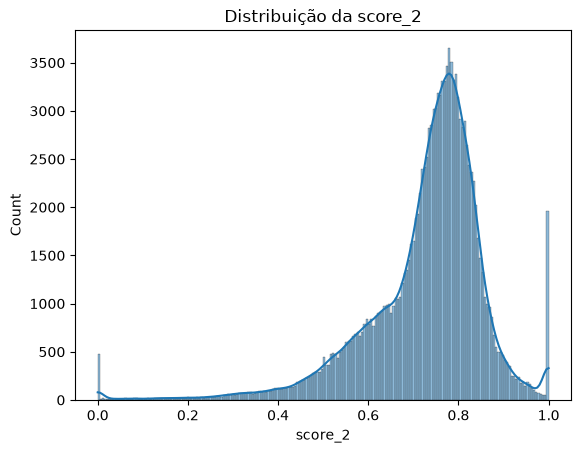

In [16]:
## Visualizando a distribuição

## Coluna score_2 apresenta uma distribuição assimétrica à esquerda.

## Isso significa que:
## A maior parte dos valores está concentrada em regiões mais altas.
## Existem valores menores formando uma cauda à esquerda.
## Esses valores baixos podem puxar a média para baixo.

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_2'].dropna(), kde=True)

plt.title('Distribuição da score_2')
plt.show()

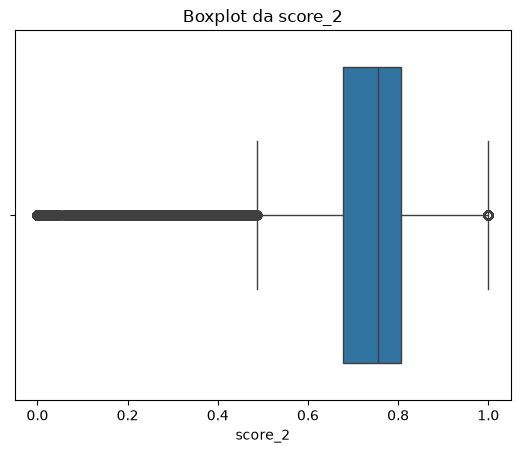

In [17]:
## Verificando outliers

sns.boxplot(x=df_complete['score_2'])

plt.title('Boxplot da score_2')
plt.show()

In [18]:
df_complete['score_2'] = df_complete['score_2'].fillna(
    df_complete['score_2'].median()
)

In [19]:
df_complete['score_2'].describe()

count    150000.000000
mean          0.730486
std           0.127292
min           0.000000
25%           0.690200
50%           0.755500
75%           0.801100
max           1.000000
Name: score_2, dtype: float64

In [20]:
df_complete['score_2'].isna().sum()

np.int64(0)

In [21]:
df_complete['score_3'].describe()

count    1.370160e+05
mean     2.604451e+05
std      8.464361e+05
min      1.600000e-01
25%      9.679915e+03
50%      4.371165e+04
75%      1.454436e+05
max      1.387874e+07
Name: score_3, dtype: float64

In [22]:
## score3
# A média está acima da mediana.
## Isso pode indicar uma distribuição com assimetria à direita, ou seja, alguns valores altos estão puxando a média para alto.
# Vamos analisar a simetria

df_complete['score_3'].skew()

np.float64(6.724388883652882)

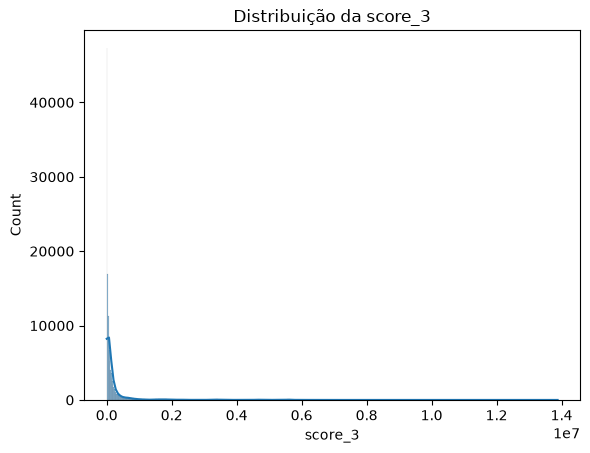

In [23]:
## Visualizando a distribuição

## Coluna score_3 apresenta uma distribuição assimétrica à direita.

## Isso significa que:
## A maior parte dos valores está concentrada em regiões mais baixas.
## Existem valores maiores formando uma cauda à direita.
## Esses valores altos podem puxar a média para alto.

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_3'].dropna(), kde=True)

plt.title('Distribuição da score_3')
plt.show()

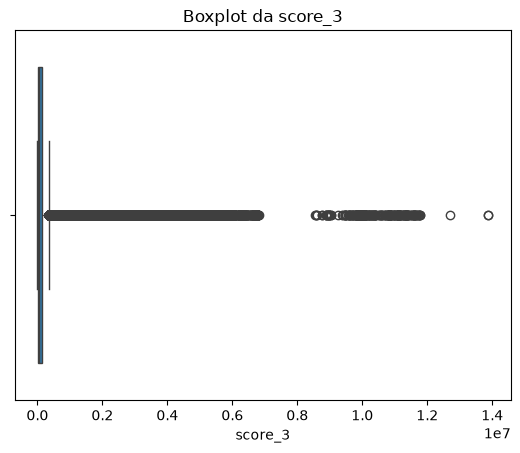

In [24]:
## Verificando outliers

sns.boxplot(x=df_complete['score_3'])

plt.title('Boxplot da score_3')
plt.show()

In [25]:
## criando uma funçao para automatizar a escolha da mediana e media

def choose_mean_or_50(df, coluna):

    dados = df[coluna].dropna()

    skew = dados.skew()

    if abs(skew) <= 0.5 and abs(skew) >= -0.5:
        print('Sugestão: avaliar a MÉDIA')
        print(f'Valor da assimetria {skew}')
        # return dados.mean()
    else:
        print('Sugestão: avaliar a MEDIANA')
        print(f'Valor da assimetria {skew}')
        if abs(skew) > 0.5:
            print("Assimetria positiva - A direita - outliers com valores altos")
        else:
            print("Assimetria negativa - A esquerda - outliers com valores baixos")
        # return dados.median()

In [26]:
choose_mean_or_50(df_complete, 'score_3')

Sugestão: avaliar a MEDIANA
Valor da assimetria 6.724388883652882
Assimetria positiva - A direita - outliers com valores altos


In [67]:
df_complete['score_3'] = df_complete['score_3'].fillna(
    df_complete['score_3'].median()
)

In [27]:
df_complete['score_3'].describe()

count    1.370160e+05
mean     2.604451e+05
std      8.464361e+05
min      1.600000e-01
25%      9.679915e+03
50%      4.371165e+04
75%      1.454436e+05
max      1.387874e+07
Name: score_3, dtype: float64

In [28]:
df_complete['score_3'].isna().sum()

np.int64(12984)

In [29]:
df_complete['score_4'].describe()

##- Grande dispersão: desvio padrão = 20,06.

count    149635.000000
mean         21.677669
std          20.062146
min           0.000000
25%           2.000000
50%          14.000000
75%          50.000000
max          50.000000
Name: score_4, dtype: float64

In [30]:
df_complete['score_4'].skew()

np.float64(0.42206955540972096)

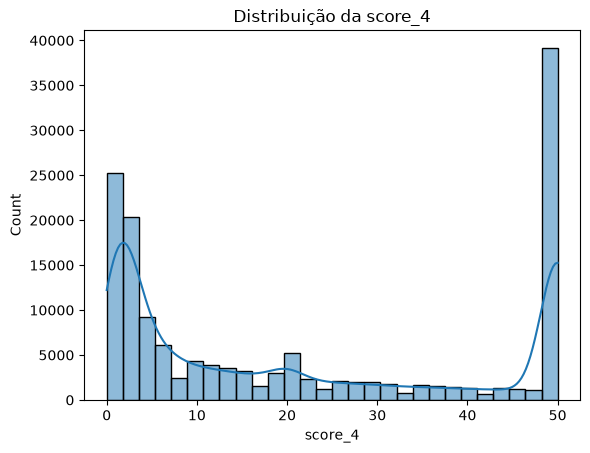

In [31]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_4'].dropna(), kde=True)

plt.title('Distribuição da score_4')
plt.show()

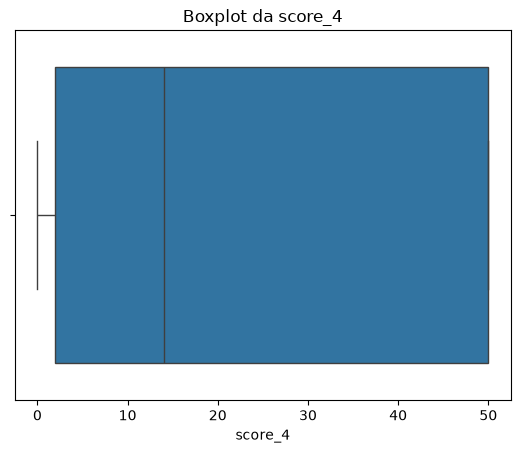

In [32]:
## O boxplot da variável score_4 apresenta elevada dispersão, com intervalo interquartil de 48 pontos (Q1 = 2 e Q3 = 50). 
## A mediana de 14 encontra-se mais próxima do primeiro quartil, indicando uma distribuição desigual dos valores dentro da caixa.
## Não foram identificados outliers pelo método do IQR. 
# ##Além disso, o terceiro quartil coincide com o valor máximo, reforçando a concentração de observações no score 50, já identificada no histograma.

sns.boxplot(x=df_complete['score_4'])

plt.title('Boxplot da score_4')
plt.show()

In [33]:
## contabilizando quantas vezes aparece cada numero - os 10 mais
df_complete["score_4"].value_counts(normalize=True).mul(100).head(10)

score_4
50.0    25.794099
1.0     16.337755
2.0      8.660407
3.0      4.975440
4.0      3.496508
20.0     2.703245
5.0      2.643098
6.0      2.214722
7.0      1.886591
8.0      1.640659
Name: proportion, dtype: float64

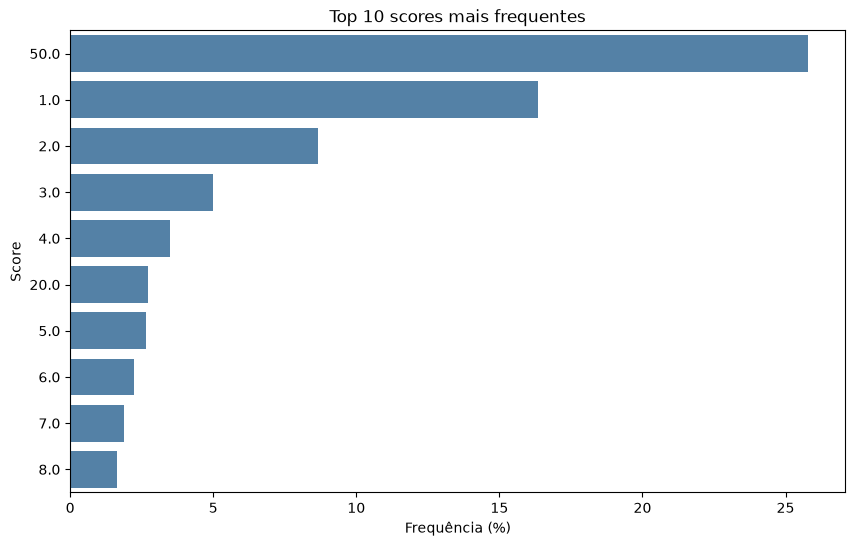

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcula a porcentagem dos 10 scores mais frequentes
frequencia = (
    df_complete["score_4"]
    .value_counts(normalize=True)
    .mul(100)
    .head(10)
)

# Cria o gráfico
plt.figure(figsize=(10, 6))

sns.barplot(
    x=frequencia.values,
    y=frequencia.index.astype(str),
    color="steelblue"
)

plt.title("Top 10 scores mais frequentes")
plt.xlabel("Frequência (%)")
plt.ylabel("Score")

plt.show()

## A variável score_4 apresenta assimetria positiva leve (0,422), média de 21,68 e mediana de 14, com elevada dispersão (desvio padrão de 20,06).

A análise de frequência revelou que 25,79% das observações possuem pontuação máxima de 50, enquanto 41,86% estão concentradas entre 1 e 8.

O histograma sugere uma distribuição bimodal, com forte concentração nos extremos e possível efeito teto. 

In [35]:
## quantidade de nulos em relaçao a quantidade total de dados
print("Nulos (%):", df_complete["score_4"].isna().mean() * 100)

Nulos (%): 0.24333333333333335


A variável `score_4` apresenta apenas 0,24% de valores ausentes. 
Considerando a baixa proporção de nulos e a concentração dos dados nos extremos, optou-se pela imputação utilizando a mediana, uma medida robusta que tende a preservar a distribuição geral da variável.



In [36]:
df_complete['score_4'] = df_complete['score_4'].fillna(
    df_complete['score_4'].median()
)

In [37]:
df_complete['score_4'].describe()

count    150000.000000
mean         21.658987
std          20.041292
min           0.000000
25%           2.000000
50%          14.000000
75%          50.000000
max          50.000000
Name: score_4, dtype: float64

In [38]:
df_complete['score_4'].isna().sum()

np.int64(0)

In [39]:
df_complete['score_6'].describe()

count    149989.000000
mean         51.169352
std         709.472904
min          -5.000000
25%           1.000000
50%           8.000000
75%          33.000000
max      145274.000000
Name: score_6, dtype: float64

In [40]:
## Assimetria positiva
df_complete['score_6'].skew()

np.float64(126.18299766329632)

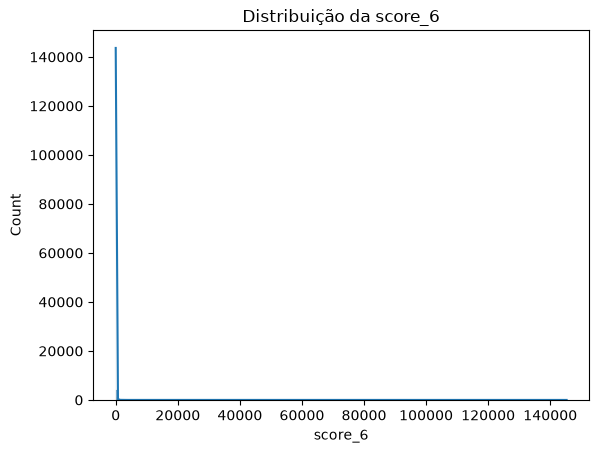

In [41]:

## Concentração próxima de zero: a grande maioria das observações possui valores relativamente baixos.
## Cauda extremamente longa à direita: existem valores que chegam a aproximadamente 145.000.
## Assimetria positiva acentuada: os valores altos se estendem muito além da região onde a maioria dos dados está concentrada.
## Distribuição não normal: o formato é muito diferente de uma distribuição normal (curva de sino).
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_6'].dropna(), kde=True)

plt.title('Distribuição da score_6')
plt.show()

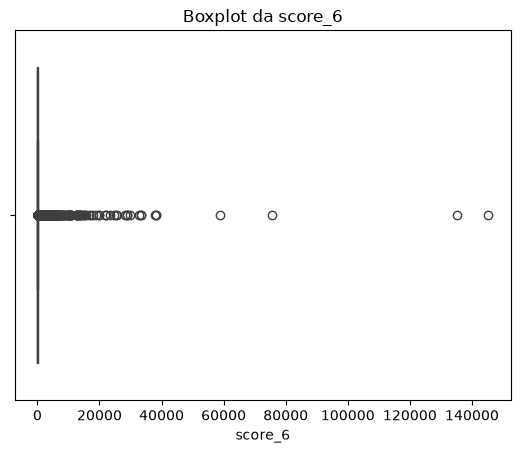

In [42]:
sns.boxplot(x=df_complete['score_6'])

plt.title('Boxplot da score_6')
plt.show()

In [43]:
print("Nulos (%):", df_complete["score_6"].isna().mean() * 100)

Nulos (%): 0.007333333333333333


## Imputação pela mediana em `score_6`
- Pouquíssimos nulos: o impacto da imputação será praticamente insignificante na distribuição geral.
- Assimetria positiva acentuada: os valores extremos podem elevar bastante a média.
- Presença de outliers: a mediana é mais robusta e menos influenciada por esses valores.

In [45]:
df_complete['score_6'] = df_complete['score_6'].fillna(
    df_complete['score_6'].median()
)

In [46]:
df_complete['score_6'].describe()

count    150000.000000
mean         51.166187
std         709.446986
min          -5.000000
25%           1.000000
50%           8.000000
75%          33.000000
max      145274.000000
Name: score_6, dtype: float64

In [47]:
df_complete['score_6'].isna().sum()

np.int64(0)

In [48]:
df_complete['score_9'].describe()

count    149989.000000
mean       2305.409403
std        1712.379601
min           0.000000
25%         910.000000
50%        1937.000000
75%        3445.000000
max        7544.000000
Name: score_9, dtype: float64

In [49]:
## Assimetria positiva
df_complete['score_9'].skew()

np.float64(0.6812243767055983)

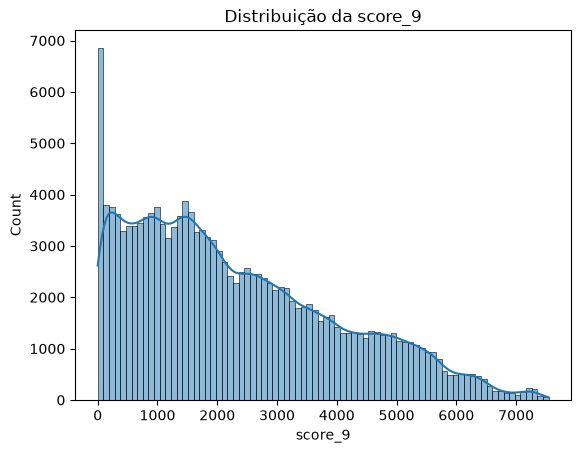

In [50]:
## Distribuiçao assimetria a direita - outliers com valores altos puxando a média para cima

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_9'].dropna(), kde=True)

plt.title('Distribuição da score_9')
plt.show()

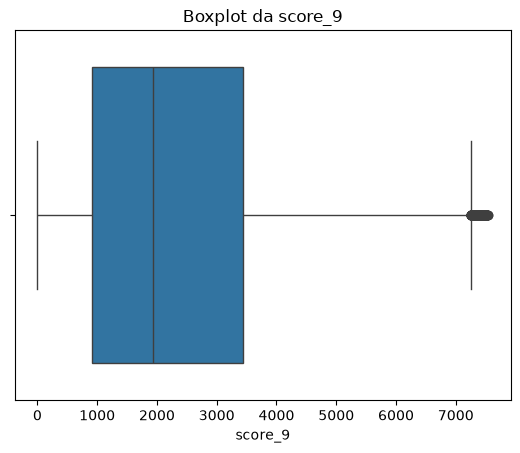

In [51]:
sns.boxplot(x=df_complete['score_9'])

plt.title('Boxplot da score_9')
plt.show()

In [52]:
df_complete['score_9'] = df_complete['score_9'].fillna(
    df_complete['score_9'].median()
)

In [53]:
df_complete['score_9'].describe()

count    150000.000000
mean       2305.382387
std        1712.319718
min           0.000000
25%         910.000000
50%        1937.000000
75%        3444.000000
max        7544.000000
Name: score_9, dtype: float64

In [54]:
df_complete['score_9'].isna().sum()

np.int64(0)

In [55]:
df_complete['score_10'].describe()

count    149635.000000
mean        299.969579
std         321.075806
min           0.000000
25%          42.000000
50%         193.000000
75%         459.000000
max        2225.000000
Name: score_10, dtype: float64

In [56]:
## Assimetria positiva
df_complete['score_10'].skew()

np.float64(1.3770509975502057)

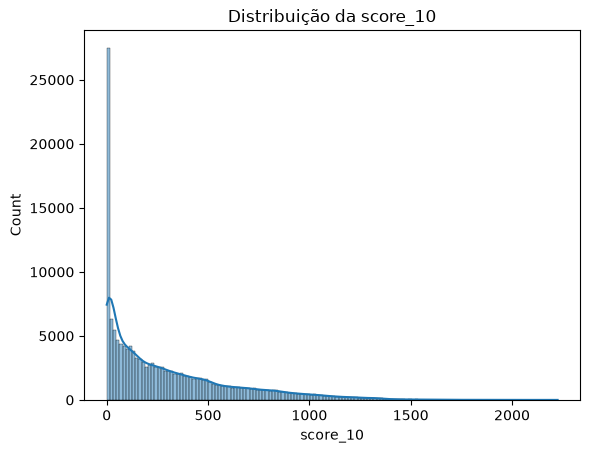

In [57]:
## Assimetria positiva - a direita - outliers com valores altos puxando a média para cima.
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_complete['score_10'].dropna(), kde=True)

plt.title('Distribuição da score_10')
plt.show()

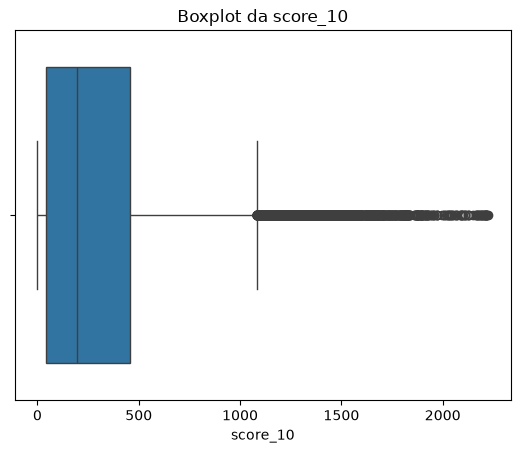

In [58]:
sns.boxplot(x=df_complete['score_10'])

plt.title('Boxplot da score_10')
plt.show()

In [59]:
df_complete['score_10'] = df_complete['score_10'].fillna(
    df_complete['score_10'].median()
)

In [60]:
df_complete['score_10'].describe()

count    150000.000000
mean        299.709287
std         320.728227
min           0.000000
25%          42.000000
50%         193.000000
75%         458.000000
max        2225.000000
Name: score_10, dtype: float64

In [61]:
df_complete['score_10'].isna().sum()

np.int64(0)

In [62]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   id_compra            150000 non-null  int64         
 1   score_1              150000 non-null  int64         
 2   score_2              150000 non-null  float64       
 3   score_3              137016 non-null  float64       
 4   score_4              150000 non-null  float64       
 5   score_5              150000 non-null  float64       
 6   score_6              150000 non-null  float64       
 7   pais                 149806 non-null  str           
 8   score_7              150000 non-null  int64         
 9   produto              150000 non-null  str           
 10  categoria_produto    150000 non-null  str           
 11  score_8              150000 non-null  float64       
 12  score_9              150000 non-null  float64       
 13  score_10             1500

In [63]:
df_complete['pais'].value_counts(dropna=False)

pais
BR     111628
AR      31964
UY       2967
US       2273
SE        358
MX        236
NaN       194
RU         73
ES         69
CO         64
GB         43
FR         18
IT         14
PT         13
DE          9
CL          9
PE          5
EC          4
PY          4
AU          3
CA          3
CH          3
CN          3
NZ          3
UA          3
BE          3
PA          3
BO          2
CR          2
NL          2
PR          2
AE          2
LB          2
KR          1
NI          1
IN          1
TR          1
DO          1
EG          1
TW          1
JP          1
ZA          1
GR          1
GE          1
AD          1
BS          1
IL          1
FI          1
HN          1
PH          1
GH          1
NO          1
Name: count, dtype: int64

In [64]:
df_complete['pais'] = df_complete['pais'].fillna('Desconhecido')
print(df_complete['pais'].isna().sum())
print(df_complete['pais'].value_counts(dropna=False))

0
pais
BR              111628
AR               31964
UY                2967
US                2273
SE                 358
MX                 236
Desconhecido       194
RU                  73
ES                  69
CO                  64
GB                  43
FR                  18
IT                  14
PT                  13
DE                   9
CL                   9
PE                   5
EC                   4
PY                   4
AU                   3
CA                   3
CH                   3
CN                   3
NZ                   3
UA                   3
BE                   3
PA                   3
BO                   2
CR                   2
NL                   2
PR                   2
AE                   2
LB                   2
KR                   1
NI                   1
IN                   1
TR                   1
DO                   1
EG                   1
TW                   1
JP                   1
ZA                   1
GR                   1
GE  

In [65]:
df_complete['entrega_doc_2'] = df_complete['entrega_doc_2'].fillna('N')
print(df_complete['entrega_doc_2'].isna().sum())
print(df_complete['entrega_doc_2'].value_counts(dropna=False))

0
entrega_doc_2
N    125909
Y     24091
Name: count, dtype: int64


In [68]:
df_complete.isna().sum()

id_compra              0
score_1                0
score_2                0
score_3                0
score_4                0
score_5                0
score_6                0
pais                   0
score_7                0
produto                0
categoria_produto      0
score_8                0
score_9                0
score_10               0
data_compra            0
valor_compra           0
score_fraude_modelo    0
fraude                 0
entrega_doc_1          0
entrega_doc_2          0
entrega_doc_3          0
dtype: int64

## Manipulação dos documentos

'N' -> 0
'Y' -> 1

In [69]:
print(df_complete['entrega_doc_1'].value_counts())
print(df_complete['entrega_doc_2'].value_counts())
print(df_complete['entrega_doc_3'].value_counts())

s = df_complete['entrega_doc_2']
print("Linhas:", len(s))
print("Ausentes:", s.isna().sum())
print(s.value_counts(dropna=False))

entrega_doc_1
1    135353
0     14647
Name: count, dtype: int64
entrega_doc_2
N    125909
Y     24091
Name: count, dtype: int64
entrega_doc_3
Y    83129
N    66871
Name: count, dtype: int64
Linhas: 150000
Ausentes: 0
entrega_doc_2
N    125909
Y     24091
Name: count, dtype: int64


In [70]:
yes_no = {'Y': 1, 'N': 0}
df_complete['entrega_doc_2'] = df_complete['entrega_doc_2'].map(yes_no)
df_complete['entrega_doc_3'] = df_complete['entrega_doc_3'].map(yes_no)

In [71]:

print(df_complete['entrega_doc_1'].value_counts())
print(df_complete['entrega_doc_2'].value_counts())
print(df_complete['entrega_doc_3'].value_counts())


entrega_doc_1
1    135353
0     14647
Name: count, dtype: int64
entrega_doc_2
0    125909
1     24091
Name: count, dtype: int64
entrega_doc_3
1    83129
0    66871
Name: count, dtype: int64


## Fraudes em países

In [72]:
df_complete['pais'].value_counts().head(10)

pais
BR              111628
AR               31964
UY                2967
US                2273
SE                 358
MX                 236
Desconhecido       194
RU                  73
ES                  69
CO                  64
Name: count, dtype: int64

## Sobre a regra do agrupamento

>Países que tem mais de 10 mil dados, podemos deixar eles por eles mesmos.
>Se eles tem menos de 10 mil, podemos agrupar com outros países.

BR e AR ficam e o resto é colocado em um único agrupamento.

In [73]:
def group_countries(pais):
    if pais in ["BR", "AR"]:
        return pais 
    else:
        return "Outro"  

In [74]:
## apply() para aplicar a funçao agrupar_paises em cada elemento da coluna 'pais'

df_complete['pais_agrupado'] = df_complete['pais'].apply(group_countries)
df_complete['pais_agrupado'].value_counts()

pais_agrupado
BR       111628
AR        31964
Outro      6408
Name: count, dtype: int64

## Transformando a funçao `agrupar paises` em funçao lambda

In [81]:
lbd_group_countries = lambda pais: pais if pais in ["BR", "AR"] else "Outro"
df_complete['pais_agrupado'] = df_complete['pais'].apply(lbd_group_countries)

In [82]:
## criando as colunas de hora_compra e dia_semana

df_complete['data_compra'].dtype

dtype('<M8[us]')

In [84]:

df_complete['dia_semana'] = df_complete['data_compra'].dt.day_of_week
df_complete['dia_semana'].unique()

array([4, 2, 6, 0, 5, 3, 1], dtype=int32)

In [85]:
days_of_week_dict = {
    0: 'Segunda',
    1: 'Terça',
    2: 'Quarta',
    3: 'Quinta',
    4: 'Sexta',
    5: 'Sabado',
    6: 'Domingo',
}

In [86]:
df_complete['dia_semana'].map(days_of_week_dict)

0           Sexta
1          Quarta
2         Domingo
3          Quarta
4         Domingo
           ...   
149995      Sexta
149996      Sexta
149997      Terça
149998    Domingo
149999    Domingo
Name: dia_semana, Length: 150000, dtype: str

In [ ]:
df_complete['hora_compra'] = df_complete['data_compra'].dt.strftime("%H:%M")